# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import WHUS2CDplusDataset
from aitlas.models import DeepLabV3, DeepLabV3_13_bands
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor
import rasterio
import numpy as np

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir": "./data/WHUS2-CD+",
    "selection":"rgb"
}
dataset = WHUS2CDplusDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 36


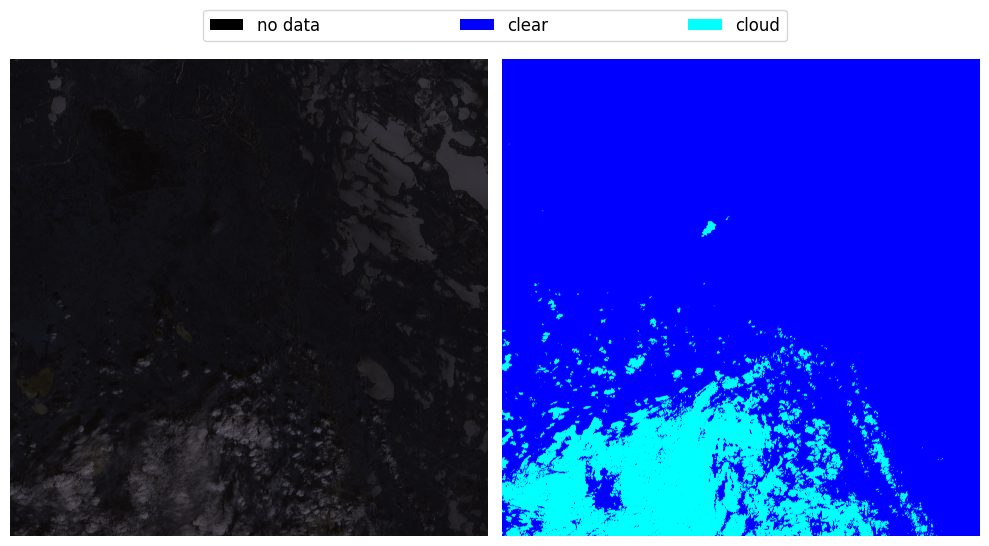

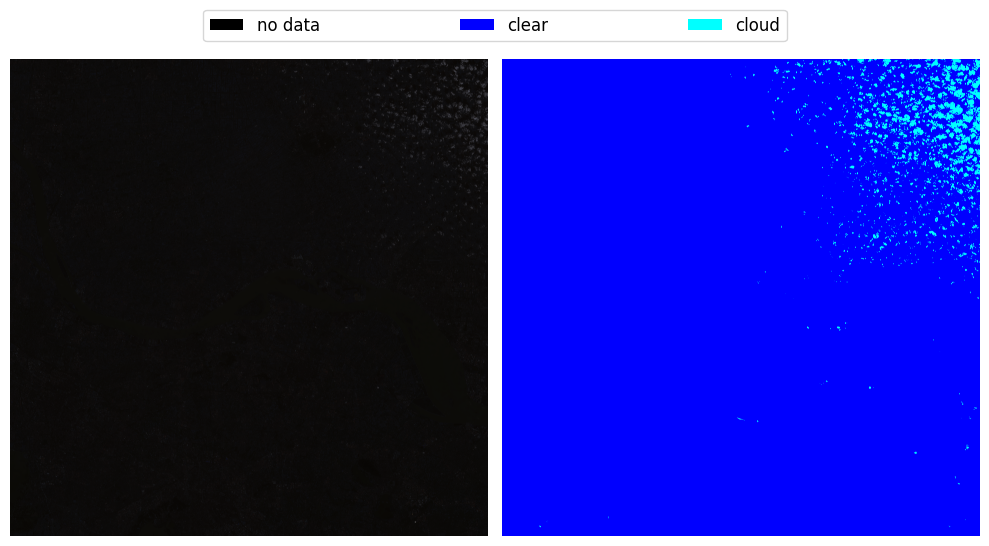

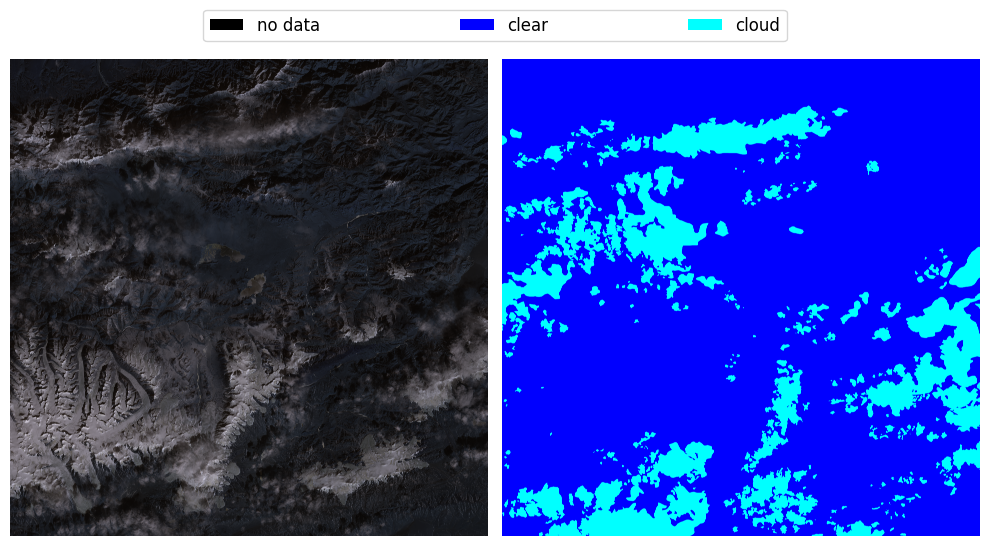

In [12]:
fig1 = dataset.show_image(6)
fig2 = dataset.show_image(21)
fig3 = dataset.show_image(30)

In [16]:
dataset.data_distribution_table()

,Number of pixels
no data,6.699593e+07
clear,3.696242e+09
cloud,5.769363e+08


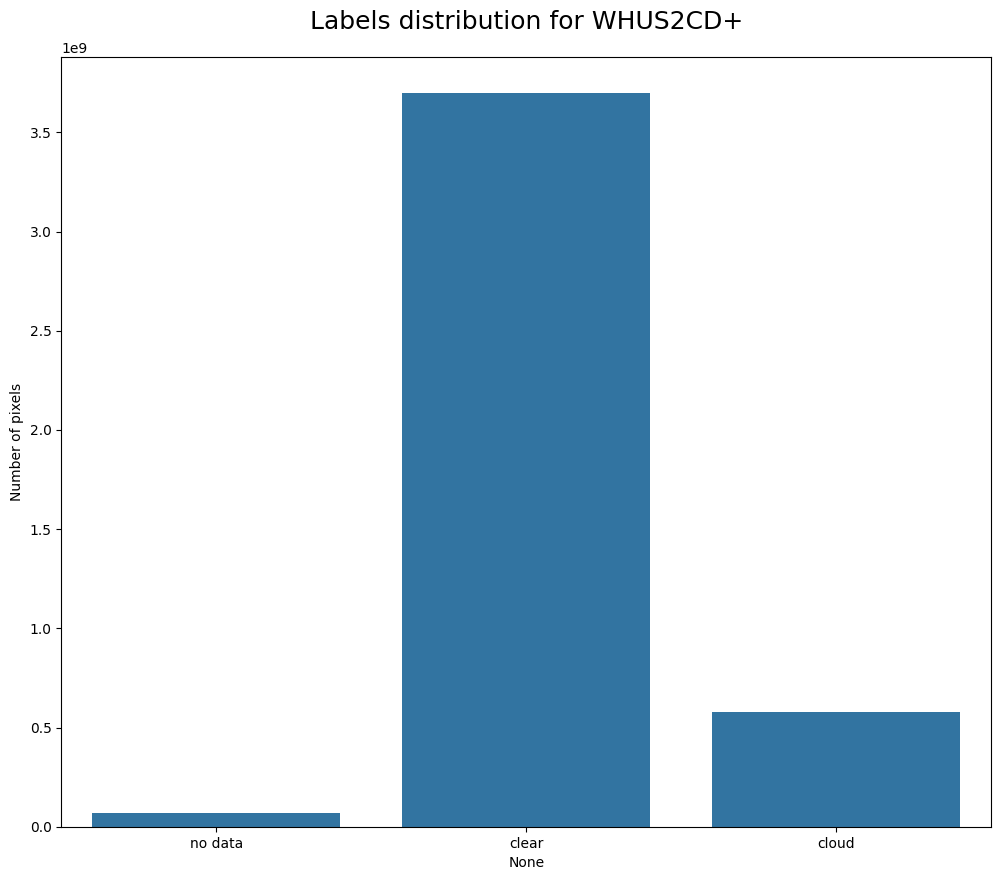

In [17]:
fig = dataset.data_distribution_barchart()

# Working with Sentinel-2 true color RGB images

## Load the training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 2,
    "shuffle": True,
    "num_workers": 0,
    "data_dir": "./data/WHUS2-CD+",
    "csv_file": "./data/WHUS2-CD+/splits/train.csv", # predefined splits
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = WHUS2CDplusDataset(train_dataset_config)
len(train_dataset)

24

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/WHUS2-CD+/rgb"
model_config = {
    "num_classes": 3, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [37]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-02 09:03:00,526 INFO Starting training.
training: 100%|██████████| 12/12 [01:36<00:00,  8.05s/it]
2025-09-02 09:04:38,064 INFO epoch: 1, time: 97, loss:  0.60371
testing on train set: 100%|██████████| 12/12 [01:36<00:00,  8.01s/it]
2025-09-02 09:06:16,116 INFO IOU:0.20502800173169514, IOU mean:0.20894213542965448, IOU per Class:[0.02622103 0.473486   0.12711937]
training: 100%|██████████| 12/12 [01:37<00:00,  8.09s/it]
2025-09-02 09:07:53,157 INFO epoch: 2, time: 97, loss:  0.55681
testing on train set: 100%|██████████| 12/12 [01:36<00:00,  8.05s/it]
2025-09-02 09:09:29,792 INFO IOU:0.11165942518997542, IOU mean:0.11459007844164282, IOU per Class:[0.02767845 0.2143052  0.10178658]
training: 100%|██████████| 12/12 [01:36<00:00,  8.07s/it]
2025-09-02 09:11:06,655 INFO epoch: 3, time: 97, loss:  0.51032
testing on train set: 100%|██████████| 12/12 [01:36<00:00,  8.03s/it]
2025-09-02 09:12:43,057 INFO IOU:0.2921105327636922, IOU mean:0.27265387346718434, IOU per Class:[0.03129757 0

0.38483111560344696

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/WHUS2-CD+",
    "csv_file": "./data/WHUS2-CD+/splits/test.csv",
    "selection": "rgb",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = WHUS2CDplusDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/WHUS2-CD+/rgb/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

12


2025-09-02 09:35:54,742 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/WHUS2-CD+/rgb/checkpoint.pth.tar
2025-09-02 09:35:56,791 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/WHUS2-CD+/rgb/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 3/3 [00:27<00:00,  9.02s/it]


[{'IOU': 0.26584162655425675,
  'IOU mean': 0.18689606058264627,
  'IOU per Class': array([0.00256136, 0.51037392, 0.0477529 ])}]

## Predictions

2025-09-02 09:38:52,020 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/WHUS2-CD+/rgb/checkpoint.pth.tar
2025-09-02 09:38:54,113 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/WHUS2-CD+/rgb/checkpoint.pth.tar at epoch 11
2025-09-02 09:38:56,879 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
2025-09-02 09:39:00,532 WARNING Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


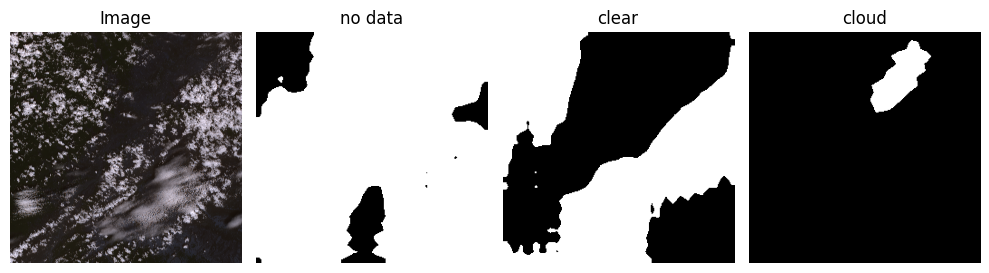

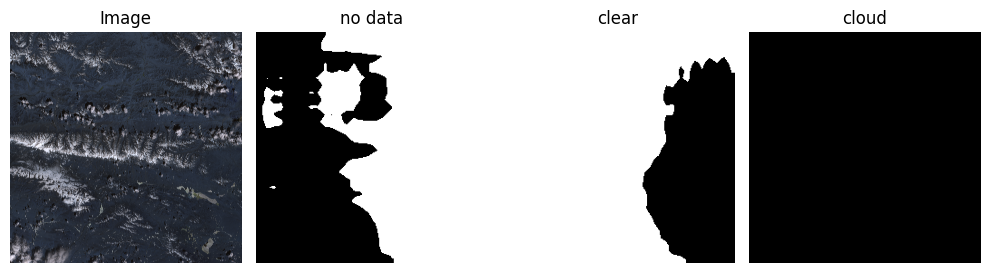

In [ ]:
model_path = "./data/experiments/WHUS2-CD+/rgb/checkpoint.pth.tar"
labels = ["no data", "clear", "cloud"]
transform = ResizeToTensor()
model.load_model(model_path)

b02_path = "./data/WHUS2-CD+/S2A_MSIL1C_20190602T021611_N0207_R003_T52TES_20190602T042019.SAFE/S2A_MSIL1C_20190602T021611_N0207_R003_T52TES_20190602T042019.SAFE/GRANULE/L1C_T52TES_A020592_20190602T021605/IMG_DATA/T52TES_20190602T021611_B02.jp2"
b03_path = "./data/WHUS2-CD+/S2A_MSIL1C_20190602T021611_N0207_R003_T52TES_20190602T042019.SAFE/S2A_MSIL1C_20190602T021611_N0207_R003_T52TES_20190602T042019.SAFE/GRANULE/L1C_T52TES_A020592_20190602T021605/IMG_DATA/T52TES_20190602T021611_B03.jp2"
b04_path = "./data/WHUS2-CD+/S2A_MSIL1C_20190602T021611_N0207_R003_T52TES_20190602T042019.SAFE/S2A_MSIL1C_20190602T021611_N0207_R003_T52TES_20190602T042019.SAFE/GRANULE/L1C_T52TES_A020592_20190602T021605/IMG_DATA/T52TES_20190602T021611_B04.jp2"
with rasterio.open(b02_path) as src:
    b02 = src.read(1)
with rasterio.open(b03_path) as src:
    b03 = src.read(1)
with rasterio.open(b04_path) as src:
    b04 = src.read(1)
# Stack as RGB
image = np.dstack((b02, b03, b04)).astype(np.float32)/10000
fig = model.predict_masks(image, labels, transform)

b02_path = "./data/WHUS2-CD+/S2A_MSIL1C_20200416T042701_N0209_R133_T46SFE_20200416T074050.SAFE/S2A_MSIL1C_20200416T042701_N0209_R133_T46SFE_20200416T074050.SAFE/GRANULE/L1C_T46SFE_A025155_20200416T042703/IMG_DATA/T46SFE_20200416T042701_B02.jp2"
b03_path = "./data/WHUS2-CD+/S2A_MSIL1C_20200416T042701_N0209_R133_T46SFE_20200416T074050.SAFE/S2A_MSIL1C_20200416T042701_N0209_R133_T46SFE_20200416T074050.SAFE/GRANULE/L1C_T46SFE_A025155_20200416T042703/IMG_DATA/T46SFE_20200416T042701_B03.jp2"
b04_path = "./data/WHUS2-CD+/S2A_MSIL1C_20200416T042701_N0209_R133_T46SFE_20200416T074050.SAFE/S2A_MSIL1C_20200416T042701_N0209_R133_T46SFE_20200416T074050.SAFE/GRANULE/L1C_T46SFE_A025155_20200416T042703/IMG_DATA/T46SFE_20200416T042701_B04.jp2"
with rasterio.open(b02_path) as src:
    b02 = src.read(1)
with rasterio.open(b03_path) as src:
    b03 = src.read(1)
with rasterio.open(b04_path) as src:
    b04 = src.read(1)
# Stack as RGB
image = np.dstack((b02, b03, b04)).astype(np.float32)/10000
fig = model.predict_masks(image, labels, transform)

# Working with the 13 bands of Sentinel-2

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 4,
    "shuffle": True,
    "num_workers": 0,
    "selection":"all",
    "data_dir": "./data/WHUS2-CD+",
    "csv_file": "./data/WHUS2-CD+/splits/train.csv",
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"],
}
train_dataset = WHUS2CDplusDataset(train_dataset_config)
len(train_dataset)

24

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/WHUS2-CD+/all_bands"
model_config = {
    "num_classes": 3, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["iou"],
    "input_dim": 13
}

model = DeepLabV3_13_bands(model_config)
model.prepare()

## Start the training

In [50]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-09-02 09:43:32,272 INFO Starting training.
training: 100%|██████████| 6/6 [29:26<00:00, 294.39s/it]
2025-09-02 10:12:59,498 INFO epoch: 1, time: 1766, loss:  0.54386
testing on train set: 100%|██████████| 6/6 [29:33<00:00, 295.57s/it]
2025-09-02 10:42:34,443 INFO IOU:0.36906901339056514, IOU mean:0.25836576335233535, IOU per Class:[0.02696054 0.67149079 0.07664596]
training: 100%|██████████| 6/6 [29:15<00:00, 292.64s/it]
2025-09-02 11:11:50,309 INFO epoch: 2, time: 1756, loss:  0.45252
testing on train set: 100%|██████████| 6/6 [29:17<00:00, 292.90s/it]
2025-09-02 11:41:07,713 INFO IOU:0.11917171991776863, IOU mean:0.13780008909019273, IOU per Class:[0.02348577 0.19190465 0.19800985]
training: 100%|██████████| 6/6 [29:12<00:00, 292.09s/it]
2025-09-02 12:10:20,263 INFO epoch: 3, time: 1753, loss:  0.40360
testing on train set: 100%|██████████| 6/6 [29:25<00:00, 294.33s/it]
2025-09-02 12:39:46,262 INFO IOU:0.13922218230944033, IOU mean:0.1885699566208721, IOU per Class:[0.02299877 0

0.28865622480710346